In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q transformers datasets accelerate scikit-learn

In [ ]:
import pandas as pd

In [ ]:
fake_df = pd.read_csv("Fake.csv", engine='python', on_bad_lines='skip')
true_df = pd.read_csv("True.csv", engine='python', on_bad_lines='skip')

In [ ]:
print(fake_df.head())

                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date  
0  December 31, 2017  
1  December 31, 2017  
2  December 30, 2017  
3  December 29, 2017  
4  December 25, 2017  


In [ ]:
print(true_df.head())

                                               title  \
0  As U.S. budget fight looms, Republicans flip t...   
1  U.S. military to accept transgender recruits o...   
2  Senior U.S. Republican senator: 'Let Mr. Muell...   
3  FBI Russia probe helped by Australian diplomat...   
4  Trump wants Postal Service to charge 'much mor...   

                                                text       subject  \
0  WASHINGTON (Reuters) - The head of a conservat...  politicsNews   
1  WASHINGTON (Reuters) - Transgender people will...  politicsNews   
2  WASHINGTON (Reuters) - The special counsel inv...  politicsNews   
3  WASHINGTON (Reuters) - Trump campaign adviser ...  politicsNews   
4  SEATTLE/WASHINGTON (Reuters) - President Donal...  politicsNews   

                 date  
0  December 31, 2017   
1  December 29, 2017   
2  December 31, 2017   
3  December 30, 2017   
4  December 29, 2017   


In [ ]:
print(fake_df.shape)
print(true_df.shape)

(23481, 4)
(21417, 4)


In [ ]:
print(fake_df.columns)

Index(['title', 'text', 'subject', 'date'], dtype='object')


In [ ]:
print("Fake news subjects:")
print(fake_df['subject'].value_counts())

print("\nReal news subjects:")
print(true_df['subject'].value_counts())

Fake news subjects:
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

Real news subjects:
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64


In [ ]:
print("Fake news subjects:")
print(fake_df['subject'].value_counts())

print("\nReal news subjects:")
print(true_df['subject'].value_counts())

Fake news subjects:
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

Real news subjects:
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64


In [ ]:
print("Fake unique subjects:")
print(fake_df['subject'].value_counts(dropna=False))

print("\nReal unique subjects:")
print(true_df['subject'].value_counts(dropna=False))

Fake unique subjects:
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

Real unique subjects:
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64


In [ ]:
print("Fake unique subjects:")
print(fake_df['subject'].value_counts(dropna=False))

print("\nReal unique subjects:")
print(true_df['subject'].value_counts(dropna=False))

Fake unique subjects:
subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

Real unique subjects:
subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64


In [ ]:
fake_df['subject'].value_counts(dropna=False)

,count
subject,
News,9050
politics,6841
left-news,4459
Government News,1570
US_News,783
Middle-east,778


In [ ]:
true_df['subject'].value_counts(dropna=False)

,count
subject,
politicsNews,11272
worldnews,10145


In [ ]:
true_df['subject'].value_counts(dropna=False)

,count
subject,
politicsNews,11272
worldnews,10145


In [ ]:
fake_df['label'] = 1
true_df['label'] = 0

In [ ]:
print(fake_df['label'].value_counts())
print(true_df['label'].value_counts())

label
1    23481
Name: count, dtype: int64
label
0    21417
Name: count, dtype: int64


In [ ]:
df = pd.concat([fake_df, true_df], ignore_index=True)

print(df.shape)

(44898, 5)


In [ ]:
print(df.shape)

print("\nLabel distribution:")
print(df['label'].value_counts())

(44898, 5)

Label distribution:
label
1    23481
0    21417
Name: count, dtype: int64


In [ ]:
df = pd.concat([fake_df, true_df], ignore_index=True)

print(df.shape)

print("\nLabel distribution:")
print(df['label'].value_counts())

(44898, 5)

Label distribution:
label
1    23481
0    21417
Name: count, dtype: int64


In [ ]:
duplicates = df['text'].duplicated().sum()

print("Duplicate articles:", duplicates)

Duplicate articles: 6252


In [ ]:
duplicates = df['text'].duplicated().sum()

print("Duplicate articles:", duplicates)

Duplicate articles: 6252


In [ ]:
df = df.drop_duplicates(subset='text', keep='first').reset_index(drop=True)

print("New dataset shape:", df.shape)
print("Remaining duplicates:", df['text'].duplicated().sum())

New dataset shape: (38646, 5)
Remaining duplicates: 0


In [ ]:
print(df['label'].value_counts())
print()
print(df['label'].value_counts(normalize=True))

label
0    21191
1    17455
Name: count, dtype: int64

label
0    0.548336
1    0.451664
Name: proportion, dtype: float64


In [ ]:
df['content'] = df['title'].fillna('') + ' ' + df['text'].fillna('')

In [ ]:
df = df[['content', 'label']]

In [ ]:
print(df.head())
print(df.shape)

                                             content  label
0   Donald Trump Sends Out Embarrassing New Year’...      1
1   Drunk Bragging Trump Staffer Started Russian ...      1
2   Sheriff David Clarke Becomes An Internet Joke...      1
3   Trump Is So Obsessed He Even Has Obama’s Name...      1
4   Pope Francis Just Called Out Donald Trump Dur...      1
(38646, 2)


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
train_texts, val_texts, train_labels, val_labels = train_test_split(
    df['content'].tolist(),
    df['label'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

In [ ]:
print("Training samples:", len(train_texts))
print("Validation samples:", len(val_texts))

print("\nTraining distribution:")
print(pd.Series(train_labels).value_counts(normalize=True))

print("\nValidation distribution:")
print(pd.Series(val_labels).value_counts(normalize=True))

Training samples: 30916
Validation samples: 7730

Training distribution:
0    0.548324
1    0.451676
Name: proportion, dtype: float64

Validation distribution:
0    0.548383
1    0.451617
Name: proportion, dtype: float64


In [ ]:
from transformers import DistilBertTokenizerFast

tokenizer = DistilBertTokenizerFast.from_pretrained(
    "distilbert-base-uncased"
)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
sample = train_texts[0]

print(sample[:500])

Top U.S. Intelligence Democrat blasts Trump over Russia report WASHINGTON (Reuters) - U.S. Senator Mark Warner, the top Democrat on the Senate Intelligence Committee, said allegations that President Donald Trump released classified information to Russia would be a “slap in the face” to the U.S. intelligence community, if true. “Risking sources & methods is inexcusable, particularly with the Russians,” Warner said in a comment on Twitter and distributed by his office, referring to a Washington Po


In [ ]:
encoded = tokenizer(
    sample,
    truncation=True,
    padding="max_length",
    max_length=256,
    return_tensors="pt"
)

In [ ]:
print(encoded.keys())
print(encoded["input_ids"].shape)
print(encoded["input_ids"][0][:20])
print(encoded["attention_mask"][0][:20])

KeysView({'input_ids': tensor([[  101,  2327,  1057,  1012,  1055,  1012,  4454,  7672, 25829,  8398,
          2058,  3607,  3189,  2899,  1006, 26665,  1007,  1011,  1057,  1012,
          1055,  1012,  5205,  2928,  6654,  1010,  1996,  2327,  7672,  2006,
          1996,  4001,  4454,  2837,  1010,  2056,  9989,  2008,  2343,  6221,
          8398,  2207,  6219,  2592,  2000,  3607,  2052,  2022,  1037,  1523,
         14308,  1999,  1996,  2227,  1524,  2000,  1996,  1057,  1012,  1055,
          1012,  4454,  2451,  1010,  2065,  2995,  1012,  1523, 26875,  4216,
          1004,  4725,  2003,  1999, 10288,  7874,  3085,  1010,  3391,  2007,
          1996, 12513,  1010,  1524,  6654,  2056,  1999,  1037,  7615,  2006,
         10474,  1998,  5500,  2011,  2010,  2436,  1010,  7727,  2000,  1037,
          2899,  2695,  3189,  2008,  8398, 21362,  6219,  2592,  2000,  3607,
          1521,  1055,  3097,  2704,  2076,  1037,  3116,  2197,  2733,  1012,
           102,     0,     0,

In [ ]:
import torch
from torch.utils.data import Dataset

In [ ]:
class FakeNewsDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        text = self.texts[idx]
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }

In [ ]:
train_dataset = FakeNewsDataset(
    train_texts,
    train_labels,
    tokenizer,
    max_length=256
)

val_dataset = FakeNewsDataset(
    val_texts,
    val_labels,
    tokenizer,
    max_length=256
)

In [ ]:
sample_item = train_dataset[0]

print(sample_item.keys())
print("input_ids shape:", sample_item["input_ids"].shape)
print("attention_mask shape:", sample_item["attention_mask"].shape)
print("label:", sample_item["labels"])

dict_keys(['input_ids', 'attention_mask', 'labels'])
input_ids shape: torch.Size([256])
attention_mask shape: torch.Size([256])
label: tensor(0)


In [ ]:
from transformers import DistilBertForSequenceClassification

model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
print(model)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


In [ ]:
print("Number of parameters:", model.num_parameters())

Number of parameters: 66955010


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Using device:", device)

Using device: cuda


In [ ]:
from torch.utils.data import DataLoader

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

In [ ]:
batch = next(iter(train_loader))

print(batch.keys())
print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)

dict_keys(['input_ids', 'attention_mask', 'labels'])
Input IDs shape: torch.Size([16, 256])
Attention mask shape: torch.Size([16, 256])
Labels shape: torch.Size([16])


In [ ]:
batch = {
    key: value.to(device)
    for key, value in batch.items()
}

In [ ]:
model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=batch["input_ids"],
        attention_mask=batch["attention_mask"]
    )

In [ ]:
print(outputs)

SequenceClassifierOutput(loss=None, logits=tensor([[-0.1986, -0.0163],
        [-0.2198, -0.0043],
        [-0.2063, -0.0139],
        [-0.1566, -0.0373],
        [-0.1885, -0.0546],
        [-0.1906, -0.0584],
        [-0.1851, -0.0728],
        [-0.2172, -0.0114],
        [-0.1851, -0.0370],
        [-0.1929, -0.0094],
        [-0.2091, -0.0185],
        [-0.2036,  0.0212],
        [-0.1821,  0.0030],
        [-0.1704, -0.0065],
        [-0.1918, -0.0537],
        [-0.1887, -0.0299]], device='cuda:0'), hidden_states=None, attentions=None)


In [ ]:
print("Logits shape:", outputs.logits.shape)

Logits shape: torch.Size([16, 2])


In [ ]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)

print("Optimizer created successfully")

Optimizer created successfully


In [ ]:
model.train()

# Get one batch
batch = next(iter(train_loader))

# Move batch to GPU
batch = {
    key: value.to(device)
    for key, value in batch.items()
}

# Clear old gradients
optimizer.zero_grad()

# Forward pass
outputs = model(
    input_ids=batch["input_ids"],
    attention_mask=batch["attention_mask"],
    labels=batch["labels"]
)

# Get loss
loss = outputs.loss

# Calculate gradients
loss.backward()

# Update model weights
optimizer.step()

print("Training step completed")
print("Loss:", loss.item())

Training step completed
Loss: 0.6870381832122803


In [ ]:
def evaluate_model(model, val_loader, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for batch in val_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )

            loss = outputs.loss
            predictions = torch.argmax(outputs.logits, dim=1)

            total_loss += loss.item()

            correct += (predictions == batch["labels"]).sum().item()
            total += batch["labels"].size(0)

    average_loss = total_loss / len(val_loader)
    accuracy = correct / total

    return average_loss, accuracy

In [ ]:
val_loss, val_accuracy = evaluate_model(
    model,
    val_loader,
    device
)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

Validation Loss: 0.6929968260536509
Validation Accuracy: 0.46235446313065975


In [ ]:
from transformers import DistilBertForSequenceClassification

model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

model = model.to(device)

# Recreate optimizer for the fresh model
optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)

print("Fresh model and optimizer ready")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Fresh model and optimizer ready


In [ ]:
import time

num_epochs = 2

for epoch in range(num_epochs):

    model.train()

    total_loss = 0
    start_time = time.time()

    for step, batch in enumerate(train_loader):

        # Move batch to GPU
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            labels=batch["labels"]
        )

        # Get loss
        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        total_loss += loss.item()

        # Show progress every 100 batches
        if (step + 1) % 100 == 0:
            print(
                f"Epoch {epoch + 1}/{num_epochs} | "
                f"Step {step + 1}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    average_train_loss = total_loss / len(train_loader)

    # Validate after each epoch
    val_loss, val_accuracy = evaluate_model(
        model,
        val_loader,
        device
    )

    epoch_time = time.time() - start_time

    print("\n" + "=" * 60)
    print(f"Epoch {epoch + 1} completed")
    print(f"Training Loss: {average_train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Time: {epoch_time / 60:.2f} minutes")
    print("=" * 60 + "\n")

Epoch 1/2 | Step 100/1933 | Loss: 0.0071
Epoch 1/2 | Step 200/1933 | Loss: 0.0029
Epoch 1/2 | Step 300/1933 | Loss: 0.0025
Epoch 1/2 | Step 400/1933 | Loss: 0.0012
Epoch 1/2 | Step 500/1933 | Loss: 0.0501


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for batch in val_loader:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(batch["labels"].cpu().numpy())


accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions)
recall = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["REAL", "FAKE"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

In [ ]:
print("Total dataframe rows:", len(df))

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

print("Train loader batches:", len(train_loader))
print("Validation loader batches:", len(val_loader))

print("Batch size:", train_loader.batch_size)

In [ ]:
print("Fake.csv rows:", len(fake_df))
print("True.csv rows:", len(true_df))

print("\nFake label count:")
print(fake_df["label"].value_counts())

print("\nTrue label count:")
print(true_df["label"].value_counts())

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["REAL", "FAKE"]
)

disp.plot()

plt.title("DistilBERT Fake News Detection - Confusion Matrix")
plt.show()

In [ ]:
def predict_news(text):

    model.eval()

    encoding = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=256,
        return_tensors="pt"
    )

    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    with torch.no_grad():

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

    probabilities = torch.softmax(outputs.logits, dim=1)

    prediction = torch.argmax(probabilities, dim=1).item()

    confidence = probabilities[0][prediction].item()

    if prediction == 0:
        label = "REAL"
    else:
        label = "FAKE"

    return label, confidence

In [ ]:
test_news = """
The Indian government announced a new policy that will provide
additional support for technology startups across the country.
"""

label, confidence = predict_news(test_news)

print("Prediction:", label)
print("Confidence:", f"{confidence * 100:.2f}%")

In [ ]:
import random

model.eval()

for i in random.sample(range(len(val_texts)), 5):

    text = val_texts[i]
    actual_label = val_labels[i]

    predicted_label, confidence = predict_news(text)

    actual_name = "REAL" if actual_label == 0 else "FAKE"

    print("=" * 70)
    print("Actual     :", actual_name)
    print("Prediction :", predicted_label)
    print("Confidence :", f"{confidence * 100:.2f}%")
    print("Text       :", text[:300], "...")

In [ ]:
model.save_pretrained("fake_news_distilbert")
tokenizer.save_pretrained("fake_news_distilbert")

print("Model and tokenizer saved successfully!")

In [ ]:
import os

print(os.listdir("/content/fake_news_distilbert"))

In [ ]:
import shutil
import os

source = "/content/fake_news_distilbert"
destination = "/content/drive/MyDrive/fake_news_distilbert"

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Model permanently saved to:")
print(destination)

In [ ]:
def predict_news(text):

    model.eval()

    encoding = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=256,
        return_tensors="pt"
    )

    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    with torch.no_grad():

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

    probabilities = torch.softmax(outputs.logits, dim=1)[0]

    real_probability = probabilities[0].item()
    fake_probability = probabilities[1].item()

    prediction = "FAKE" if fake_probability > real_probability else "REAL"

    return {
        "prediction": prediction,
        "real_probability": real_probability,
        "fake_probability": fake_probability
    }

In [ ]:
news = """
Scientists have announced a new technology that could significantly
improve the efficiency of solar panels.
"""

result = predict_news(news)

print("Prediction:", result["prediction"])
print("REAL probability:", f"{result['real_probability'] * 100:.2f}%")
print("FAKE probability:", f"{result['fake_probability'] * 100:.2f}%")

In [ ]:
from IPython.display import display
import ipywidgets as widgets

news_input = widgets.Textarea(
    value='',
    placeholder='Paste the news article here...',
    description='News:',
    layout=widgets.Layout(width='100%', height='250px')
)

predict_button = widgets.Button(
    description='Predict',
    button_style='primary'
)

output = widgets.Output()

def on_predict_clicked(b):

    with output:
        output.clear_output()

        text = news_input.value.strip()

        if not text:
            print("Please enter some news text.")
            return

        result = predict_news(text)

        print("Prediction:", result["prediction"])
        print(
            "REAL probability:",
            f"{result['real_probability'] * 100:.2f}%"
        )
        print(
            "FAKE probability:",
            f"{result['fake_probability'] * 100:.2f}%"
        )

predict_button.on_click(on_predict_clicked)

display(news_input)
display(predict_button)
display(output)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(train_texts)
X_val_tfidf = tfidf.transform(val_texts)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Training Logistic Regression...")

lr_model.fit(
    X_train_tfidf,
    train_labels
)

print("Logistic Regression training completed!")

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Make predictions
lr_predictions = lr_model.predict(X_val_tfidf)

# Calculate metrics
lr_accuracy = accuracy_score(val_labels, lr_predictions)
lr_precision = precision_score(val_labels, lr_predictions)
lr_recall = recall_score(val_labels, lr_predictions)
lr_f1 = f1_score(val_labels, lr_predictions)

print("Logistic Regression Results")
print("=" * 40)

print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

print("\nClassification Report:")
print(
    classification_report(
        val_labels,
        lr_predictions,
        target_names=["REAL", "FAKE"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(val_labels, lr_predictions))


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# Use a smaller TF-IDF representation for this audit
audit_vectorizer = TfidfVectorizer(
    max_features=20000,
    stop_words="english"
)

X_train_audit = audit_vectorizer.fit_transform(train_texts)
X_val_audit = audit_vectorizer.transform(val_texts)

print("Train matrix:", X_train_audit.shape)
print("Validation matrix:", X_val_audit.shape)

# Find the most similar training article for each validation article
similarity = cosine_similarity(
    X_val_audit,
    X_train_audit
)

max_similarity = similarity.max(axis=1)

print("\nSimilarity statistics:")
print("Minimum:", max_similarity.min())
print("Mean   :", max_similarity.mean())
print("Maximum:", max_similarity.max())

print("\nVery high similarity:")
print(">= 0.90:", (max_similarity >= 0.90).sum())
print(">= 0.95:", (max_similarity >= 0.95).sum())
print(">= 0.99:", (max_similarity >= 0.99).sum())

In [ ]:
import numpy as np

# Find the training article with maximum similarity
best_train_indices = similarity.argmax(axis=1)

# Create a small audit table
audit_results = []

for val_idx, train_idx in enumerate(best_train_indices):

    sim = max_similarity[val_idx]

    if sim >= 0.99:

        audit_results.append({
            "validation_index": val_idx,
            "training_index": train_idx,
            "similarity": sim,
            "validation_label": val_labels[val_idx],
            "training_label": train_labels[train_idx]
        })

audit_df = pd.DataFrame(audit_results)

print("Articles with similarity >= 0.99:")
print(len(audit_df))

print("\nLabel combinations:")
print(
    audit_df.groupby(
        ["training_label", "validation_label"]
    ).size()
)

print("\nFirst 20:")
print(audit_df.head(20))

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

# Combine the original train and validation text/labels
all_texts = train_texts + val_texts
all_labels = train_labels + val_labels

n_train = len(train_texts)
n_total = len(all_texts)

# Start with every article in its own group
parent = list(range(n_total))


# ---------- Union-Find functions ----------

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a


# ---------- Connect highly similar articles ----------

for val_idx, train_idx in zip(
    np.where(max_similarity >= 0.99)[0],
    best_train_indices[max_similarity >= 0.99]
):

    # Convert validation index to combined-data index
    global_val_idx = n_train + val_idx

    # Training index is already a combined-data index
    global_train_idx = train_idx

    union(global_val_idx, global_train_idx)


# Create group IDs
group_map = {}

groups = []

for i in range(n_total):

    root = find(i)

    if root not in group_map:
        group_map[root] = len(group_map)

    groups.append(group_map[root])


groups = np.array(groups)

print("Total articles:", n_total)
print("Number of similarity groups:", len(np.unique(groups)))

print("Articles connected to another article:",
      n_total - sum(
          np.bincount(groups) == 1
      ))

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Get the first 80/20 split
train_idx, val_idx = next(
    sgkf.split(
        all_texts,
        all_labels,
        groups=groups
    )
)

robust_train_texts = [all_texts[i] for i in train_idx]
robust_val_texts = [all_texts[i] for i in val_idx]

robust_train_labels = [all_labels[i] for i in train_idx]
robust_val_labels = [all_labels[i] for i in val_idx]

print("Robust training articles:", len(robust_train_texts))
print("Robust validation articles:", len(robust_val_texts))

print("\nTraining labels:")
print(pd.Series(robust_train_labels).value_counts())

print("\nValidation labels:")
print(pd.Series(robust_val_labels).value_counts())


In [ ]:
robust_train_dataset = FakeNewsDataset(
    robust_train_texts,
    robust_train_labels,
    tokenizer,
    max_length=256
)

robust_val_dataset = FakeNewsDataset(
    robust_val_texts,
    robust_val_labels,
    tokenizer,
    max_length=256
)

robust_train_loader = DataLoader(
    robust_train_dataset,
    batch_size=16,
    shuffle=True
)

robust_val_loader = DataLoader(
    robust_val_dataset,
    batch_size=16,
    shuffle=False
)

print("Robust datasets created!")
print("Training batches:", len(robust_train_loader))
print("Validation batches:", len(robust_val_loader))

In [ ]:
from transformers import DistilBertForSequenceClassification
from torch.optim import AdamW

# Fresh model
robust_model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

robust_model = robust_model.to(device)

# Fresh optimizer
robust_optimizer = AdamW(
    robust_model.parameters(),
    lr=2e-5
)

print("Fresh robust model ready")

In [ ]:
import time

num_epochs = 2

for epoch in range(num_epochs):

    robust_model.train()

    total_loss = 0
    start_time = time.time()

    for step, batch in enumerate(robust_train_loader):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        robust_optimizer.zero_grad()

        outputs = robust_model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            labels=batch["labels"]
        )

        loss = outputs.loss

        loss.backward()

        robust_optimizer.step()

        total_loss += loss.item()

        if (step + 1) % 100 == 0:
            print(
                f"Epoch {epoch + 1}/{num_epochs} | "
                f"Step {step + 1}/{len(robust_train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    average_train_loss = total_loss / len(robust_train_loader)

    # Validation
    robust_model.eval()

    correct = 0
    total = 0
    val_total_loss = 0

    with torch.no_grad():

        for batch in robust_val_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = robust_model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )

            val_total_loss += outputs.loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            correct += (
                predictions == batch["labels"]
            ).sum().item()

            total += batch["labels"].size(0)

    average_val_loss = (
        val_total_loss / len(robust_val_loader)
    )

    val_accuracy = correct / total

    epoch_time = time.time() - start_time

    print("\n" + "=" * 60)
    print(f"Epoch {epoch + 1} completed")
    print(f"Training Loss: {average_train_loss:.4f}")
    print(f"Validation Loss: {average_val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Time: {epoch_time / 60:.2f} minutes")
    print("=" * 60 + "\n")

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

model_path = "/content/drive/MyDrive/fake_news_distilbert"

if os.path.exists(model_path):
    print("Model folder found!")
    print(os.listdir(model_path))
else:
    print("Model folder not found. Check your Drive path.")

Mounted at /content/drive
Model folder found!
['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


In [2]:
import os

model_path = "/content/drive/MyDrive/fake_news_distilbert"

for file in os.listdir(model_path):
    full_path = os.path.join(model_path, file)
    size_mb = os.path.getsize(full_path) / (1024 * 1024)

    print(f"{file} — {size_mb:.2f} MB")

config.json — 0.00 MB
model.safetensors — 255.43 MB
tokenizer.json — 0.68 MB
tokenizer_config.json — 0.00 MB


In [3]:
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification
)
import torch

model_path = "/content/drive/MyDrive/fake_news_distilbert"

tokenizer = DistilBertTokenizerFast.from_pretrained(model_path)
model = DistilBertForSequenceClassification.from_pretrained(model_path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

print("Tokenizer loaded:", tokenizer.__class__.__name__)
print("Model loaded:", model.__class__.__name__)
print("Number of labels:", model.config.num_labels)
print("Device:", device)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Tokenizer loaded: DistilBertTokenizer
Model loaded: DistilBertForSequenceClassification
Number of labels: 2
Device: cuda


In [5]:
import os

drive_root = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_root):
    for filename in files:
        if filename in ["Fake.csv", "True.csv"]:
            print(os.path.join(root, filename))

In [6]:
import os

print("Current directory:", os.getcwd())
print("\nFiles in current directory:")
print(os.listdir("/content"))

print("\nFiles in MyDrive:")
print(os.listdir("/content/drive/MyDrive")[:50])

Current directory: /content

Files in current directory:
['.config', 'Fake.csv', 'drive', 'True.csv', 'sample_data']

Files in MyDrive:
['Classroom', 'soft copy.jpg', 'Certificate_digital Productivity.pdf', 'vhx-bwgq-vxj - Aug 17, 2024.pdf', 'FLEXOR.zip', 'WhatsApp Image 2024-08-30 at 18.45.41_15754a2a.jpg', 'Neeri OPR - 128.docx', 'mnrega .pptx', '_Getintopc.com_Adobe_Photoshop_2023_v24.2.0.315.rar', 'Colab Notebooks', 'Google Earth', 'Copy of Zero1 - Rent vs EMI Debate .gsheet', 'Copy of Educational (Responses).gsheet', 'Aryan_eductional.gsheet', 'Document from Aryan.pdf', 'VID-20250428-WA0072.mp4', 'Shot by Harshill Utsav K A', 'POSTED', 'DAV_01.gdoc', '20250626_182028.jpg', '20250602_204335.jpg', 'IMG-20250729-WA0013.jpg', 'Copy of Influencer Prospecting Tracker.gsheet', 'Sikkim', 'Saved from the Google app', 'Abstract Colorful Motion Background, Pink Looping - Free Stock Footage - Free Motion Background Loop (1080p, h264).mp4', 'Rose Day (1).mp4', 'Rose Day.mp4', 'PE3 1-6 Output.d

In [7]:
import pandas as pd
import os

fake_path = "/content/Fake.csv"
true_path = "/content/True.csv"

fake_df = pd.read_csv(fake_path)
true_df = pd.read_csv(true_path)

print("Fake dataset shape:", fake_df.shape)
print("Real dataset shape:", true_df.shape)

print("\nFake dataset columns:")
print(fake_df.columns.tolist())

print("\nReal dataset columns:")
print(true_df.columns.tolist())

print("\nMissing text values:")
print("Fake:", fake_df["text"].isna().sum())
print("Real:", true_df["text"].isna().sum())


Fake dataset shape: (23481, 4)
Real dataset shape: (21417, 4)

Fake dataset columns:
['title', 'text', 'subject', 'date']

Real dataset columns:
['title', 'text', 'subject', 'date']

Missing text values:
Fake: 0
Real: 0


In [8]:
import pandas as pd

# Create labels: 1 = FAKE, 0 = REAL
fake_clean = fake_df.copy()
real_clean = true_df.copy()

fake_clean["label"] = 1
real_clean["label"] = 0

# Combine both datasets
df = pd.concat(
    [fake_clean, real_clean],
    ignore_index=True
)

print("Rows before duplicate removal:", len(df))
print("Exact duplicate article texts:", df["text"].duplicated().sum())

# Remove duplicate article texts
df = df.drop_duplicates(
    subset="text",
    keep="first"
).reset_index(drop=True)

# Combine title and article text
df["content"] = (
    df["title"].fillna("")
    + " "
    + df["text"].fillna("")
).str.strip()

# Keep only the model input and label
df = df[["content", "label"]].copy()

print("\nCleaned dataset shape:", df.shape)
print("\nLabel distribution:")
print(df["label"].value_counts().sort_index().rename(
    index={0: "REAL", 1: "FAKE"}
))

print("\nRemaining duplicate content:", df["content"].duplicated().sum())


Rows before duplicate removal: 44898
Exact duplicate article texts: 6252

Cleaned dataset shape: (38646, 2)

Label distribution:
label
REAL    21191
FAKE    17455
Name: count, dtype: int64

Remaining duplicate content: 2


In [9]:
from sklearn.model_selection import train_test_split

train_texts, val_texts, train_labels, val_labels = train_test_split(
    df["content"].tolist(),
    df["label"].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training articles:", len(train_texts))
print("Validation articles:", len(val_texts))

print("\nTraining label distribution:")
print(pd.Series(train_labels).value_counts().sort_index())

print("\nValidation label distribution:")
print(pd.Series(val_labels).value_counts().sort_index())

Training articles: 30916
Validation articles: 7730

Training label distribution:
0    16952
1    13964
Name: count, dtype: int64

Validation label distribution:
0    4239
1    3491
Name: count, dtype: int64


In [10]:
# Convert training and validation text to sets
train_content_set = set(train_texts)

# Count validation articles whose exact content appears in training
exact_overlap = sum(
    text in train_content_set
    for text in val_texts
)

print("Validation articles:", len(val_texts))
print("Exact content overlaps with training:", exact_overlap)
print(
    "Percentage of validation with exact overlap:",
    round(exact_overlap / len(val_texts) * 100, 4),
    "%"
)

Validation articles: 7730
Exact content overlaps with training: 0
Percentage of validation with exact overlap: 0.0 %


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Convert articles into TF-IDF features
vectorizer = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    dtype=np.float32
)

X_train_audit = vectorizer.fit_transform(train_texts)
X_val_audit = vectorizer.transform(val_texts)

print("Training feature shape:", X_train_audit.shape)
print("Validation feature shape:", X_val_audit.shape)

# Compare in small batches to reduce RAM usage
max_similarities = []

batch_size = 100

for start in range(0, X_val_audit.shape[0], batch_size):
    end = min(start + batch_size, X_val_audit.shape[0])

    similarities = cosine_similarity(
        X_val_audit[start:end],
        X_train_audit
    )

    max_similarities.extend(similarities.max(axis=1))

max_similarities = np.array(max_similarities)

print("\n--- Near-Duplicate Audit ---")
print("Minimum similarity:", round(float(max_similarities.min()), 4))
print("Mean similarity:", round(float(max_similarities.mean()), 4))
print("Maximum similarity:", round(float(max_similarities.max()), 4))

for threshold in [0.90, 0.95, 0.99]:
    count = int((max_similarities >= threshold).sum())
    percentage = count / len(val_texts) * 100

    print(
        f"Similarity >= {threshold}: "
        f"{count} articles ({percentage:.2f}%)"
    )

Training feature shape: (30916, 20000)
Validation feature shape: (7730, 20000)

--- Near-Duplicate Audit ---
Minimum similarity: 0.121
Mean similarity: 0.497
Maximum similarity: 1.0
Similarity >= 0.9: 184 articles (2.38%)
Similarity >= 0.95: 153 articles (1.98%)
Similarity >= 0.99: 111 articles (1.44%)


In [12]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

max_similarities = []
closest_train_indices = []

batch_size = 100

for start in range(0, X_val_audit.shape[0], batch_size):
    end = min(start + batch_size, X_val_audit.shape[0])

    similarities = cosine_similarity(
        X_val_audit[start:end],
        X_train_audit
    )

    closest_indices = similarities.argmax(axis=1)
    closest_scores = similarities.max(axis=1)

    closest_train_indices.extend(closest_indices.tolist())
    max_similarities.extend(closest_scores.tolist())

max_similarities = np.array(max_similarities)
closest_train_indices = np.array(closest_train_indices)

# Find the 10 most similar validation-training pairs
top_indices = np.argsort(max_similarities)[-10:][::-1]

for rank, val_idx in enumerate(top_indices, start=1):
    train_idx = closest_train_indices[val_idx]

    print(f"\n{'=' * 60}")
    print(f"PAIR {rank} | Similarity: {max_similarities[val_idx]:.4f}")
    print(f"Training label: {train_labels[train_idx]} "
          f"({'FAKE' if train_labels[train_idx] == 1 else 'REAL'})")
    print(f"Validation label: {val_labels[val_idx]} "
          f"({'FAKE' if val_labels[val_idx] == 1 else 'REAL'})")
    print(f"Labels match: {train_labels[train_idx] == val_labels[val_idx]}")

    print("\nTRAINING ARTICLE:")
    print(train_texts[train_idx][:500])

    print("\nVALIDATION ARTICLE:")
    print(val_texts[val_idx][:500])



PAIR 1 | Similarity: 1.0000
Training label: 0 (REAL)
Validation label: 0 (REAL)
Labels match: True

TRAINING ARTICLE:
U.S. Congress members decry 'ethnic cleansing' in Myanmar; Suu Kyi doubts allegations YANGON/NAYPYITAW (Reuters) - Members of the U.S. Congress said on Tuesday operations carried out against the Rohingya Muslims in Myanmar had  all the hallmarks  of ethnic cleansing, while the country s leader Aung San Suu Kyi expressed doubts about allegations of rights abuses. The U.S. Senate members also said they were disturbed by a  violent and disproportionate  security response to Rohingya militant attack

VALIDATION ARTICLE:
U.S. Congress members decry 'ethnic cleansing' in Myanmar; Suu Kyi doubts allegations YANGON/NAYPYITAW (Reuters) - Members of the U.S. Congress said on Tuesday operations carried out against the Rohingya Muslims in Myanmar had “all the hallmarks” of ethnic cleansing, while the country’s leader Aung San Suu Kyi expressed doubts about allegations of rights ab

In [13]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

# Work from the cleaned df containing content and label
texts = df["content"].tolist()
labels = df["label"].to_numpy()

# Normalize punctuation/spacing differences for duplicate detection
import re
import unicodedata

def normalize_text(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

normalized_texts = [normalize_text(t) for t in texts]

# TF-IDF representation for finding similar articles
group_vectorizer = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    dtype=np.float32
)
X_groups = group_vectorizer.fit_transform(normalized_texts)

# Find close neighbors efficiently
neighbors = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=10,
    n_jobs=-1
)
neighbors.fit(X_groups)

distances, indices = neighbors.kneighbors(X_groups)

# Join articles with similarity >= 0.95
# Similarity = 1 - cosine distance
rows, cols = [], []
threshold = 0.95

for i in range(len(texts)):
    for distance, j in zip(distances[i], indices[i]):
        if i != j and (1.0 - distance) >= threshold:
            rows.append(i)
            cols.append(j)

graph = coo_matrix(
    (np.ones(len(rows), dtype=np.uint8), (rows, cols)),
    shape=(len(texts), len(texts))
).tocsr()

graph = graph.maximum(graph.T)
n_groups, groups = connected_components(graph, directed=False)

print("Articles:", len(texts))
print("Similarity groups:", n_groups)
print("Articles linked to another:", int(np.bincount(groups).max()))

Articles: 38646
Similarity groups: 38238
Articles linked to another: 6


In [14]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

# Create five group-aware folds while approximately preserving class balance
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X=np.zeros(len(df)),
        y=df["label"].to_numpy(),
        groups=groups
    )
)

# Create separate variables; keep the original split untouched
robust_train_texts = df.iloc[train_idx]["content"].tolist()
robust_val_texts = df.iloc[val_idx]["content"].tolist()

robust_train_labels = df.iloc[train_idx]["label"].tolist()
robust_val_labels = df.iloc[val_idx]["label"].tolist()

print("Robust training articles:", len(robust_train_texts))
print("Robust validation articles:", len(robust_val_texts))

print("\nTraining labels:")
print(pd.Series(robust_train_labels).value_counts().sort_index())

print("\nValidation labels:")
print(pd.Series(robust_val_labels).value_counts().sort_index())

print("\nGroups shared between splits:",
      len(set(groups[train_idx]) & set(groups[val_idx])))

Robust training articles: 30919
Robust validation articles: 7727

Training labels:
0    16950
1    13969
Name: count, dtype: int64

Validation labels:
0    4241
1    3486
Name: count, dtype: int64

Groups shared between splits: 0


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Fit the audit vectorizer on training articles only
robust_vectorizer = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    dtype=np.float32
)

X_robust_train = robust_vectorizer.fit_transform(
    robust_train_texts
)
X_robust_val = robust_vectorizer.transform(
    robust_val_texts
)

# Find each validation article's closest training article
robust_max_similarities = []

for start in range(0, X_robust_val.shape[0], 100):
    end = min(start + 100, X_robust_val.shape[0])

    similarities = cosine_similarity(
        X_robust_val[start:end],
        X_robust_train
    )

    robust_max_similarities.extend(
        similarities.max(axis=1)
    )

robust_max_similarities = np.asarray(
    robust_max_similarities
)

print("Mean maximum similarity:",
      round(float(robust_max_similarities.mean()), 4))

print("Maximum similarity:",
      round(float(robust_max_similarities.max()), 4))

for threshold in [0.90, 0.95, 0.99]:
    count = int(
        (robust_max_similarities >= threshold).sum()
    )
    print(
        f"Similarity >= {threshold}: "
        f"{count} articles "
        f"({count / len(robust_val_texts) * 100:.2f}%)"
    )

Mean maximum similarity: 0.4888
Maximum similarity: 0.9492
Similarity >= 0.9: 31 articles (0.40%)
Similarity >= 0.95: 0 articles (0.00%)
Similarity >= 0.99: 0 articles (0.00%)


In [16]:
# Check whether our robust split variables exist
required_variables = [
    "robust_train_texts",
    "robust_val_texts",
    "robust_train_labels",
    "robust_val_labels"
]

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'Missing'}")

robust_train_texts: Available
robust_val_texts: Available
robust_train_labels: Available
robust_val_labels: Available


In [17]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizerFast

# Use the pretrained DistilBERT tokenizer
tokenizer = DistilBertTokenizerFast.from_pretrained(
    "distilbert-base-uncased"
)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Tokenizer loaded successfully!")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

PyTorch version: 2.11.0+cu130
GPU available: True
Tokenizer loaded successfully!


In [18]:
class FakeNewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        text = str(self.texts[index])
        label = int(self.labels[index])

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }

print("FakeNewsDataset class created successfully!")


FakeNewsDataset class created successfully!


In [19]:
# Create PyTorch datasets
train_dataset = FakeNewsDataset(
    robust_train_texts,
    robust_train_labels,
    tokenizer,
    max_length=256
)

val_dataset = FakeNewsDataset(
    robust_val_texts,
    robust_val_labels,
    tokenizer,
    max_length=256
)

# Create DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training articles:", len(train_dataset))
print("Validation articles:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training articles: 30919
Validation articles: 7727
Training batches: 1933
Validation batches: 483


In [20]:
from transformers import DistilBertForSequenceClassification

# Start from the original pretrained DistilBERT checkpoint
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("Model initialized successfully!")
print("Device:", device)
print("Number of labels:", model.config.num_labels)
print("Label mapping:", model.config.id2label)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model initialized successfully!
Device: cuda
Number of labels: 2
Label mapping: {0: 'LABEL_0', 1: 'LABEL_1'}


In [22]:
import os

# Human-readable class labels
model.config.id2label = {0: "REAL", 1: "FAKE"}
model.config.label2id = {"REAL": 0, "FAKE": 1}

# Training configuration
EPOCHS = 2
LEARNING_RATE = 2e-5

# Create a NEW folder so the original model is never overwritten
ROBUST_MODEL_PATH = "/content/drive/MyDrive/fake_news_distilbert_robust"
os.makedirs(ROBUST_MODEL_PATH, exist_ok=True)

# Optimizer updates the model's trainable weights using PyTorch's native AdamW
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Training configuration ready!")
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Device:", device)
print("New model save path:", ROBUST_MODEL_PATH)

Training configuration ready!
Epochs: 2
Learning rate: 2e-05
Device: cuda
New model save path: /content/drive/MyDrive/fake_news_distilbert_robust


In [23]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from tqdm.auto import tqdm
import numpy as np

best_f1 = -1.0
training_history = []

for epoch in range(EPOCHS):
    print(f"\n{'='*20} Epoch {epoch + 1}/{EPOCHS} {'='*20}")

    # Training phase
    model.train()
    total_train_loss = 0.0

    progress_bar = tqdm(train_loader, desc="Training")

    for batch in progress_bar:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    avg_train_loss = total_train_loss / len(train_loader)

    # Validation phase
    model.eval()
    total_val_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(val_loader, desc="Validation"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_val_loss += outputs.loss.item()
            predictions = torch.argmax(outputs.logits, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)

    accuracy = accuracy_score(all_labels, all_predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="binary",
        zero_division=0
    )

    print(f"\nTrain loss:      {avg_train_loss:.4f}")
    print(f"Validation loss: {avg_val_loss:.4f}")
    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Precision:       {precision:.4f}")
    print(f"Recall:          {recall:.4f}")
    print(f"F1 score:        {f1:.4f}")

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

    # Save the best model so far, in the separate folder
    if f1 > best_f1:
        best_f1 = f1
        model.save_pretrained(ROBUST_MODEL_PATH)
        tokenizer.save_pretrained(ROBUST_MODEL_PATH)
        print(f"Best model saved! Validation F1: {best_f1:.4f}")

print("\nTraining complete!")
print("Best validation F1:", round(best_f1, 4))
print("Saved model folder:", ROBUST_MODEL_PATH)


==================== Epoch 1/2 ====================


Training:   0%|          | 0/1933 [00:00<?, ?it/s]

Validation:   0%|          | 0/483 [00:00<?, ?it/s]


Train loss:      0.0136
Validation loss: 0.0039
Accuracy:        0.9992
Precision:       0.9986
Recall:          0.9997
F1 score:        0.9991


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved! Validation F1: 0.9991

==================== Epoch 2/2 ====================


Training:   0%|          | 0/1933 [00:00<?, ?it/s]

Validation:   0%|          | 0/483 [00:00<?, ?it/s]


Train loss:      0.0019
Validation loss: 0.0033
Accuracy:        0.9992
Precision:       0.9986
Recall:          0.9997
F1 score:        0.9991

Training complete!
Best validation F1: 0.9991
Saved model folder: /content/drive/MyDrive/fake_news_distilbert_robust


In [24]:
import pandas as pd

history_df = pd.DataFrame(training_history)

display(
    history_df.round(4)
)

,epoch,train_loss,val_loss,accuracy,precision,recall,f1
0,1,0.0136,0.0039,0.9992,0.9986,0.9997,0.9991
1,2,0.0019,0.0033,0.9992,0.9986,0.9997,0.9991


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

              precision    recall  f1-score   support

        REAL     0.9998    0.9988    0.9993      4241
        FAKE     0.9986    0.9997    0.9991      3486

    accuracy                         0.9992      7727
   macro avg     0.9992    0.9993    0.9992      7727
weighted avg     0.9992    0.9992    0.9992      7727



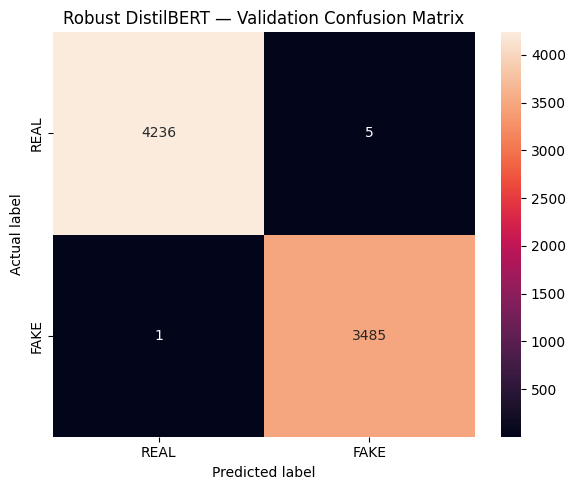

In [25]:
from sklearn.metrics import classification_report, confusion_matrix
from transformers import DistilBertForSequenceClassification
import seaborn as sns
import matplotlib.pyplot as plt
import torch

# Reload the best saved checkpoint
best_model = DistilBertForSequenceClassification.from_pretrained(
    ROBUST_MODEL_PATH
).to(device)

best_model.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = best_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(outputs.logits, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_true_labels.extend(labels.cpu().numpy())

print(classification_report(
    all_true_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["REAL", "FAKE"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["REAL", "FAKE"],
    yticklabels=["REAL", "FAKE"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Robust DistilBERT — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [26]:
# Collect validation errors
error_indices = [
    i for i, (true_label, pred_label)
    in enumerate(zip(all_true_labels, all_predictions))
    if true_label != pred_label
]

print("Total misclassified articles:", len(error_indices))

for i in error_indices:
    actual = "FAKE" if all_true_labels[i] == 1 else "REAL"
    predicted = "FAKE" if all_predictions[i] == 1 else "REAL"

    print("\n" + "=" * 70)
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Article:")
    print(robust_val_texts[i][:1200])

Total misclassified articles: 6

Actual: FAKE
Predicted: REAL
Article:
Energy Department To Close Office Of International Climate And Technology In response to the U.S. withdrawing from the Paris climate agreement earlier this month, the Energy Department is shutting down the Office of International Climate and Technology, a department that works with other countries to develop clean energy technology.An agency spokesman tried to justify the Energy Department shutting down the office by stating that the DOE is  looking for ways to consolidate the many duplicative programs that currently exist within DOE,  thus the Office of International Climate and Technology is getting the chop.The 11-person office has been in operation since 2010, operating as a means for the U.S. to work with international partners on energy sector technology in an effort to reduce greenhouse gases. The employees of the Office of International Climate and Technology also play a large part in the Clean Energy Minist

In [27]:
import pandas as pd

error_records = []

for i in error_indices:
    error_records.append({
        "actual_label": (
            "FAKE" if all_true_labels[i] == 1 else "REAL"
        ),
        "predicted_label": (
            "FAKE" if all_predictions[i] == 1 else "REAL"
        ),
        "article": robust_val_texts[i]
    })

errors_df = pd.DataFrame(error_records)

errors_path = "/content/phase1_misclassified_articles.csv"
errors_df.to_csv(errors_path, index=False)

print("Misclassified articles:", len(errors_df))
print("Saved to:", errors_path)
display(errors_df[["actual_label", "predicted_label"]])

Misclassified articles: 6
Saved to: /content/phase1_misclassified_articles.csv


,actual_label,predicted_label
0,FAKE,REAL
1,REAL,FAKE
2,REAL,FAKE
3,REAL,FAKE
4,REAL,FAKE
5,REAL,FAKE


In [29]:
import os
import json
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# Calculate metrics from the saved model's validation predictions
precision, recall, f1, _ = precision_recall_fscore_support(
    all_true_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

results = {
    "model": "Robust DistilBERT",
    "validation_articles": len(all_true_labels),
    "accuracy": accuracy_score(all_true_labels, all_predictions),
    "weighted_precision": precision,
    "weighted_recall": recall,
    "weighted_f1": f1,
    "confusion_matrix": confusion_matrix(
        all_true_labels, all_predictions, labels=[0, 1]
    ).tolist(),
    "training_epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "max_length": 256,
    "best_validation_f1_during_training": best_f1
}

results_dir = "/content/phase1_results"
os.makedirs(results_dir, exist_ok=True)

with open(
    os.path.join(results_dir, "robust_distilbert_metrics.json"),
    "w"
) as f:
    json.dump(results, f, indent=4)

pd.DataFrame(training_history).to_csv(
    os.path.join(results_dir, "training_history.csv"),
    index=False
)

errors_df.to_csv(
    os.path.join(results_dir, "misclassified_articles.csv"),
    index=False
)

print("Phase 1 results exported!")
print("Files:", os.listdir(results_dir))
print(json.dumps(results, indent=2))

Phase 1 results exported!
Files: ['training_history.csv', 'misclassified_articles.csv', 'robust_distilbert_metrics.json']
{
  "model": "Robust DistilBERT",
  "validation_articles": 7727,
  "accuracy": 0.9992235020059531,
  "weighted_precision": 0.9992241214695003,
  "weighted_recall": 0.9992235020059531,
  "weighted_f1": 0.9992235414462688,
  "confusion_matrix": [
    [
      4236,
      5
    ],
    [
      1,
      3485
    ]
  ],
  "training_epochs": 2,
  "batch_size": 16,
  "learning_rate": 2e-05,
  "max_length": 256,
  "best_validation_f1_during_training": 0.9991399082568807
}


In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
import json
import numpy as np
import os

# Convert news articles into TF-IDF features
baseline_vectorizer = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    dtype=np.float32
)

X_train = baseline_vectorizer.fit_transform(robust_train_texts)
X_val = baseline_vectorizer.transform(robust_val_texts)

print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)

# Train the baseline model on the same robust split
baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train, robust_train_labels)

# Evaluate on the same validation articles
baseline_predictions = baseline_model.predict(X_val)

baseline_accuracy = accuracy_score(
    robust_val_labels,
    baseline_predictions
)

print("\nTF-IDF + Logistic Regression results")
print("Accuracy:", round(baseline_accuracy, 4))

print(classification_report(
    robust_val_labels,
    baseline_predictions,
    labels=[0, 1],
    target_names=["REAL", "FAKE"],
    digits=4,
    zero_division=0
))

Training feature shape: (30919, 50000)
Validation feature shape: (7727, 50000)

TF-IDF + Logistic Regression results
Accuracy: 0.9832
              precision    recall  f1-score   support

        REAL     0.9795    0.9901    0.9848      4241
        FAKE     0.9878    0.9748    0.9812      3486

    accuracy                         0.9832      7727
   macro avg     0.9836    0.9824    0.9830      7727
weighted avg     0.9832    0.9832    0.9832      7727



In [33]:
import os
import json
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

baseline_precision, baseline_recall, baseline_f1, _ = (
    precision_recall_fscore_support(
        robust_val_labels,
        baseline_predictions,
        average="weighted",
        zero_division=0
    )
)

baseline_results = {
    "model": "TF-IDF + Logistic Regression",
    "validation_articles": len(robust_val_labels),
    "accuracy": accuracy_score(robust_val_labels, baseline_predictions),
    "weighted_precision": baseline_precision,
    "weighted_recall": baseline_recall,
    "weighted_f1": baseline_f1,
    "confusion_matrix": confusion_matrix(
        robust_val_labels,
        baseline_predictions,
        labels=[0, 1]
    ).tolist()
}

with open(
    "/content/phase1_results/logistic_regression_metrics.json",
    "w"
) as f:
    json.dump(baseline_results, f, indent=4)

comparison_df = pd.DataFrame([
    {
        "model": "TF-IDF + Logistic Regression",
        "accuracy": accuracy_score(
            robust_val_labels, baseline_predictions
        ),
        "weighted_f1": baseline_f1
    },
    {
        "model": "Robust DistilBERT",
        "accuracy": accuracy_score(
            all_true_labels, all_predictions
        ),
        "weighted_f1": f1
    }
])

comparison_df.to_csv(
    "/content/phase1_results/model_comparison.csv",
    index=False
)

display(comparison_df.round(4))
print("Saved baseline metrics and model comparison.")

,model,accuracy,weighted_f1
0,TF-IDF + Logistic Regression,0.9832,0.9832
1,Robust DistilBERT,0.9992,0.9992


Saved baseline metrics and model comparison.


In [34]:
import os

print("=== Phase 1 results ===")
for filename in sorted(os.listdir("/content/phase1_results")):
    path = os.path.join("/content/phase1_results", filename)
    print(f"{filename} — {os.path.getsize(path):,} bytes")

print("\n=== Google Drive model folders ===")
for path in [
    "/content/drive/MyDrive/fake_news_distilbert",
    "/content/drive/MyDrive/fake_news_distilbert_robust"
]:
    print(f"\n{path}")
    if os.path.isdir(path):
        print("Files:", sorted(os.listdir(path)))
    else:
        print("Folder not found")


=== Phase 1 results ===
logistic_regression_metrics.json — 384 bytes
misclassified_articles.csv — 26,208 bytes
model_comparison.csv — 150 bytes
robust_distilbert_metrics.json — 532 bytes
training_history.csv — 296 bytes

=== Google Drive model folders ===

/content/drive/MyDrive/fake_news_distilbert
Files: ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']

/content/drive/MyDrive/fake_news_distilbert_robust
Files: ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


In [35]:
import os

matches = []

search_roots = [
    "/content",
    "/content/drive/MyDrive"
]

for root in search_roots:
    for current_dir, dirs, files in os.walk(root):
        # Avoid searching large or irrelevant folders
        dirs[:] = [
            d for d in dirs
            if d not in [
                ".git", "node_modules", ".cache",
                "__pycache__", ".config"
            ]
        ]

        if "Fake_News_Detection_Robustness_Upgrade.ipynb" in files:
            matches.append(
                os.path.join(
                    current_dir,
                    "Fake_News_Detection_Robustness_Upgrade.ipynb"
                )
            )

print("Notebook matches found:", len(matches))

for path in matches:
    print(path)


Notebook matches found: 2
/content/drive/MyDrive/Colab Notebooks/Fake_News_Detection_Robustness_Upgrade.ipynb
/content/drive/MyDrive/Colab Notebooks/Fake_News_Detection_Robustness_Upgrade.ipynb


In [36]:
%cd /content

!git clone https://github.com/sukh0i57/fake-news-detection-distilbert.git


/content
Cloning into 'fake-news-detection-distilbert'...
remote: Enumerating objects: 20, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 20 (delta 2), reused 15 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (20/20), 360.97 KiB | 1.64 MiB/s, done.
Resolving deltas: 100% (2/2), done.
